<a href="https://colab.research.google.com/github/ad23b1012/Software-Engineering-Project/blob/main/Copy_of_DIP_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# IMPORTANT: RUN THIS CELL IN ORDER TO IMPORT YOUR KAGGLE DATA SOURCES,
# THEN FEEL FREE TO DELETE THIS CELL.
# NOTE: THIS NOTEBOOK ENVIRONMENT DIFFERS FROM KAGGLE'S PYTHON
# ENVIRONMENT SO THERE MAY BE MISSING LIBRARIES USED BY YOUR
# NOTEBOOK.
import kagglehub
sabarinathan_istd_dataset_path = kagglehub.dataset_download('sabarinathan/istd-dataset')

print('Data source import complete.')


100%|██████████| 2.00G/2.00G [00:17<00:00, 119MB/s]

Extracting files...


Data source import complete.


In [2]:
# Cell 1: imports and GPU setup
import os, sys, glob, math, random
from pathlib import Path
import numpy as np
import cv2
from tqdm import tqdm
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

# GPU config for Kaggle
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)
torch.backends.cudnn.benchmark = True

Device: cuda


In [3]:
import os

base_path = os.path.join(sabarinathan_istd_dataset_path, "ISTD_Dataset")

print("Folders:", os.listdir(base_path))

Folders: ['test', 'train']


In [4]:
import os

base_path = os.path.join(sabarinathan_istd_dataset_path, "ISTD_Dataset")

print("Folders:", os.listdir(base_path))

# Check train folders
train_path = os.path.join(base_path, "train")
print("Train:", os.listdir(train_path))

# Check test folders
test_path = os.path.join(base_path, "test")
print("Test:", os.listdir(test_path))

Folders: ['test', 'train']
Train: ['train_B', 'train_C', 'train_A']
Test: ['test_A', 'test_C', 'test_B']


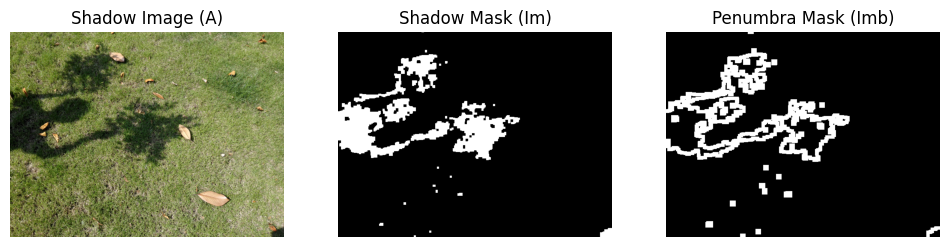

In [5]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Correcting the BASE path to use the dynamically set dataset path
BASE = os.path.join(sabarinathan_istd_dataset_path, "ISTD_Dataset", "train")

def generate_shadow_mask(img_path):
    img = cv2.imread(img_path)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    hsv = cv2.cvtColor(img, cv2.COLOR_RGB2HSV)
    h, s, v = cv2.split(hsv)

    # Basic shadow detection
    shadow_mask = ((v < 80) & (s < 120)).astype(np.uint8) * 255

    # Morphology
    kernel = np.ones((5,5), np.uint8)
    shadow_mask = cv2.morphologyEx(shadow_mask, cv2.MORPH_CLOSE, kernel)
    shadow_mask = cv2.morphologyEx(shadow_mask, cv2.MORPH_OPEN, kernel)

    # Penumbra mask
    dil = cv2.dilate(shadow_mask, kernel, iterations=2)
    ero = cv2.erode(shadow_mask, kernel, iterations=2)
    penumbra = cv2.subtract(dil, ero)

    return img, shadow_mask, penumbra


# TEST ON ONE SAMPLE
sample_a = os.path.join(BASE, "train_A", os.listdir(os.path.join(BASE, "train_A"))[0])

img, mask, pen = generate_shadow_mask(sample_a)

plt.figure(figsize=(12,4))
plt.subplot(1,3,1); plt.imshow(img); plt.title("Shadow Image (A)"); plt.axis("off")
plt.subplot(1,3,2); plt.imshow(mask, cmap='gray'); plt.title("Shadow Mask (Im)"); plt.axis("off")
plt.subplot(1,3,3); plt.imshow(pen, cmap='gray'); plt.title("Penumbra Mask (Imb)"); plt.axis("off")
plt.show()

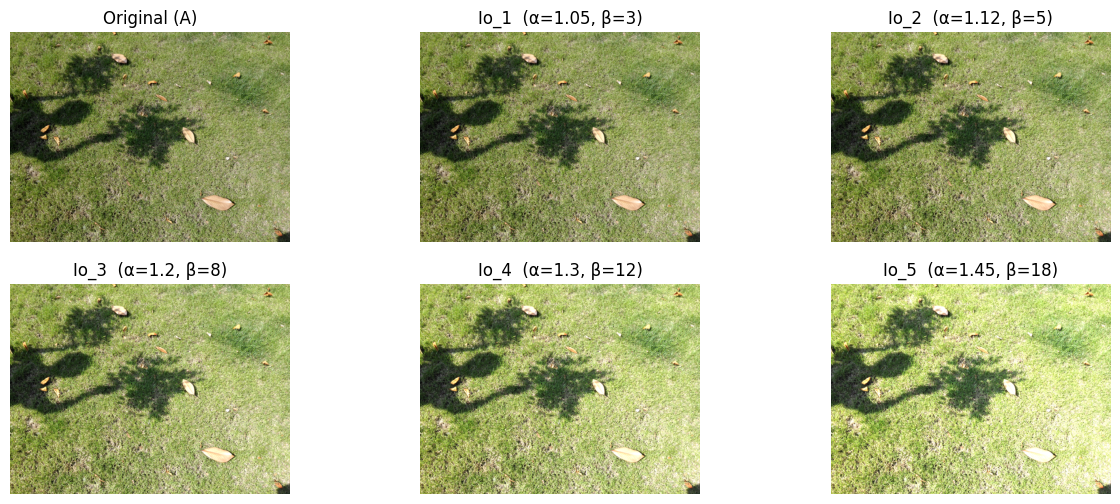

In [6]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import os

# Exposure multipliers and offsets
alpha_values = [1.05, 1.12, 1.20, 1.30, 1.45]
beta_values  = [3,    5,    8,    12,   18]

def generate_exposures(img):
    exposures = []
    for a, b in zip(alpha_values, beta_values):
        # Apply exposure: Io = a * I + b
        exp = img.astype(np.float32) * a + b
        exp = np.clip(exp, 0, 255).astype(np.uint8)
        exposures.append(exp)
    return exposures


# Test on a sample image
sample_a = os.path.join(BASE, "train_A", os.listdir(os.path.join(BASE, "train_A"))[0])

img = cv2.imread(sample_a)
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

# Generate multi-exposure sequence
exps = generate_exposures(img_rgb)

# Display results
plt.figure(figsize=(15, 6))
plt.subplot(2,3,1); plt.imshow(img_rgb); plt.title("Original (A)"); plt.axis("off")

for i, e in enumerate(exps):
    plt.subplot(2,3,i+2)
    plt.imshow(e)
    plt.title(f"Io_{i+1}  (α={alpha_values[i]}, β={beta_values[i]})")
    plt.axis("off")

plt.show()


In [7]:
import os
import cv2
import numpy as np
from tqdm import tqdm

BASE = os.path.join(sabarinathan_istd_dataset_path, "ISTD_Dataset")
OUT = "/kaggle/working/shadow-removal-project/data/processed"

os.makedirs(OUT, exist_ok=True)
os.makedirs(f"{OUT}/train", exist_ok=True)
os.makedirs(f"{OUT}/test", exist_ok=True)

def generate_masks_and_exposures(img_path):
    img = cv2.imread(img_path)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    # ---- Shadow mask ----
    hsv = cv2.cvtColor(img, cv2.COLOR_RGB2HSV)
    h, s, v = cv2.split(hsv)
    shadow_mask = (((v < 80) & (s < 120)).astype(np.uint8) * 255)

    # Morphology
    kernel = np.ones((5,5), np.uint8)
    shadow_mask = cv2.morphologyEx(shadow_mask, cv2.MORPH_CLOSE, kernel)
    shadow_mask = cv2.morphologyEx(shadow_mask, cv2.MORPH_OPEN, kernel)

    # ---- Penumbra mask ----
    dil = cv2.dilate(shadow_mask, kernel, iterations=2)
    ero = cv2.erode(shadow_mask, kernel, iterations=2)
    penumbra = cv2.subtract(dil, ero)

    # ---- Exposure images ----
    alphas = [1.05, 1.12, 1.20, 1.30, 1.45]
    betas  = [3, 5, 8, 12, 18]

    exposures = []
    for a, b in zip(alphas, betas):
        Io = np.clip(a * img + b, 0, 255).astype(np.uint8)
        exposures.append(Io)

    return img, shadow_mask, penumbra, exposures


def process_split(split):
    print(f"Processing {split}...")

    folder_A = os.path.join(BASE, split, f"{split}_A")
    folder_B = os.path.join(BASE, split, f"{split}_B")

    out_dir = os.path.join(OUT, split)

    files = sorted(os.listdir(folder_A))

    for fname in tqdm(files):
        path_A = os.path.join(folder_A, fname)
        path_B = os.path.join(folder_B, fname)

        A, mask, pen, exps = generate_masks_and_exposures(path_A)

        cv2.imwrite(f"{out_dir}/{fname}", cv2.cvtColor(A, cv2.COLOR_RGB2BGR))
        cv2.imwrite(f"{out_dir}/{fname.replace('.png','_mask.png')}", mask)
        cv2.imwrite(f"{out_dir}/{fname.replace('.png','_penumbra.png')}", pen)
        cv2.imwrite(f"{out_dir}/{fname.replace('.png','_B.png')}", cv2.cvtColor(cv2.imread(path_B), cv2.COLOR_BGR2RGB))

        for idx, Io in enumerate(exps):
            cv2.imwrite(f"{out_dir}/{fname.replace('.png', f'_Io{idx+1}.png')}", cv2.cvtColor(Io, cv2.COLOR_RGB2BGR))


# ---- Run for train & test ----
process_split("train")
process_split("test")

print("PHASE 1.3 COMPLETED ✔")

Processing train...


100%|██████████| 1330/1330 [03:30<00:00,  6.33it/s]


Processing test...


100%|██████████| 540/540 [01:24<00:00,  6.39it/s]

PHASE 1.3 COMPLETED ✔


In [8]:
# Cell 1 - imports & paths
import os
from pathlib import Path
import cv2
import numpy as np
from tqdm.notebook import tqdm
import matplotlib.pyplot as plt

# Project paths (adjust if needed)
BASE_INPUT = Path(sabarinathan_istd_dataset_path) / "ISTD_Dataset"
WORKDIR = Path("/kaggle/working/shadow-removal-project")
RAW_DIR = WORKDIR / "data" / "raw"
PROC_DIR = WORKDIR / "data" / "processed"

# ensure processed directories exist
for sub in ["train_A", "train_B", "train_C", "test_A", "test_B", "test_C"]:
    (PROC_DIR / sub).mkdir(parents=True, exist_ok=True)

print("BASE_INPUT:", BASE_INPUT)
print("Output processed folder:", PROC_DIR)

BASE_INPUT: /root/.cache/kagglehub/datasets/sabarinathan/istd-dataset/versions/1/ISTD_Dataset
Output processed folder: /kaggle/working/shadow-removal-project/data/processed


In [9]:
# Cell 2 - helpers
def imread_rgb(path):
    bgr = cv2.imread(str(path), cv2.IMREAD_COLOR)
    if bgr is None:
        raise FileNotFoundError(path)
    rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
    return rgb

def imwrite_rgb(path, img_rgb):
    bgr = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2BGR)
    cv2.imwrite(str(path), bgr)

def show_triplet(img_rgb, mask=None, pen=None, figsize=(12,4), titles=None):
    cols = 1 + (mask is not None) + (pen is not None)
    plt.figure(figsize=figsize)
    i = 1
    plt.subplot(1, cols, i); plt.imshow(img_rgb); plt.axis("off"); plt.title(titles[0] if titles else "Image"); i+=1
    if mask is not None:
        plt.subplot(1, cols, i); plt.imshow(mask, cmap="gray"); plt.axis("off"); plt.title(titles[1] if titles else "Shadow mask"); i+=1
    if pen is not None:
        plt.subplot(1, cols, i); plt.imshow(pen, cmap="gray"); plt.axis("off"); plt.title(titles[2] if titles else "Penumbra");
    plt.show()


In [10]:
# Cell 3 - shadow & penumbra mask generator (traditional)
def generate_shadow_and_penumbra(img_rgb,
                                 v_thresh=80,
                                 s_thresh=120,
                                 morph_kernel_size=7,
                                 dilate_iters=7,
                                 erode_iters=7,
                                 debug=False):
    """
    Returns:
      shadow_mask: uint8 0/255 image (shadow area = 255)
      penumbra_mask: uint8 0/255 image (boundary region)
    Parameters are tunable; ISTD images often need fairly large kernels.
    """
    img_bgr = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2BGR)
    hsv = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2HSV)
    h, s, v = cv2.split(hsv)

    # initial shadow mask (binary 0/255)
    shadow_mask = (((v < v_thresh) & (s < s_thresh))).astype(np.uint8) * 255

    # morphological clean-up
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (morph_kernel_size, morph_kernel_size))
    shadow_mask = cv2.morphologyEx(shadow_mask, cv2.MORPH_CLOSE, kernel, iterations=1)
    shadow_mask = cv2.morphologyEx(shadow_mask, cv2.MORPH_OPEN, kernel, iterations=1)

    # make penumbra: dilate - erode
    dil = cv2.dilate(shadow_mask, kernel, iterations=dilate_iters)
    ero = cv2.erode(shadow_mask, kernel, iterations=erode_iters)
    penumbra = cv2.subtract(dil, ero)

    if debug:
        print("shadow fraction:", shadow_mask.mean()/255.0)
        print("penumbra fraction:", penumbra.mean()/255.0)
    return shadow_mask, penumbra


In [11]:
# Cell 4 - generate exposure bracket Io_i (semi-data-driven)
def compute_exposures(img_rgb, shadow_mask, n_exposures=5, clamp_alpha=(0.9, 1.6)):
    """
    Generate list of N over-exposed images Io_i.
    Strategy:
      - compute mean intensity in Y (luma) for shadow vs non-shadow
      - median alpha = mean_nonshadow / (mean_shadow + eps)
      - create N alphas by interpolation around median (paper uses interpolation)
      - compute Io = alpha * I + beta where beta is small offset (scaled)
    Returns list of RGB uint8 images and alpha/beta lists.
    """
    img = img_rgb.astype(np.float32)
    eps = 1e-6

    # convert to Y (luma) for brightness estimate; use cv2.cvtColor for correct conversion
    img_yuv = cv2.cvtColor(cv2.cvtColor(img.astype(np.uint8), cv2.COLOR_RGB2BGR), cv2.COLOR_BGR2YUV)
    Y = img_yuv[:,:,0].astype(np.float32)

    shadow_mask_bool = (shadow_mask > 128)
    nonshadow_mask_bool = ~shadow_mask_bool

    mean_shadow = Y[shadow_mask_bool].mean() if shadow_mask_bool.any() else Y.mean()
    mean_non = Y[nonshadow_mask_bool].mean() if nonshadow_mask_bool.any() else Y.mean()

    median_alpha = float(mean_non / (mean_shadow + eps))
    # clamp to avoid extreme scaling
    median_alpha = float(max(min(median_alpha, clamp_alpha[1]), clamp_alpha[0]))

    # interpolation factors around median (symmetric)
    # e.g., N=5 -> factors [0.95, 0.98, 1.0, 1.02, 1.05] times median alpha
    spans = np.linspace(0.95, 1.05, num=n_exposures)
    alphas = [median_alpha * float(s) for s in spans]

    # choose beta proportional to alpha change (small shift)
    base_beta = 0.0
    betas = [base_beta + (a - 1.0) * 12.0 for a in alphas]  # tweak 12.0 to control brightness shifts

    ios = []
    for a, b in zip(alphas, betas):
        Io = img * a + b
        Io = np.clip(Io, 0, 255).astype(np.uint8)
        ios.append(Io)

    return ios, alphas, betas


In [12]:
# Cell 5 - process dataset and save outputs
# You already showed train_A/B/C and test_* present.
subsets = {
    "train_A": BASE_INPUT / "train" / "train_A",
    "train_B": BASE_INPUT / "train" / "train_B",
    "train_C": BASE_INPUT / "train" / "train_C",
    "test_A": BASE_INPUT / "test" / "test_A",
    "test_B": BASE_INPUT / "test" / "test_B",
    "test_C": BASE_INPUT / "test" / "test_C",
}

# Choose parameters
N_EXPOSURES = 5
V_THR = 80
S_THR = 120
MORPH_K = 7
DIL_IT = 7
ERO_IT = 7

for key, folder in subsets.items():
    in_files = sorted(list(folder.glob("*.png"))) # Changed glob pattern to *.png
    out_dir = PROC_DIR / key
    images_out = out_dir / "images"
    masks_out = out_dir / "masks"
    exposures_out = out_dir / "exposures"
    pen_out = out_dir / "penumbra"
    images_out.mkdir(parents=True, exist_ok=True)
    masks_out.mkdir(parents=True, exist_ok=True)
    exposures_out.mkdir(parents=True, exist_ok=True)
    pen_out.mkdir(parents=True, exist_ok=True)

    print(f"\nProcessing {key} -> {len(in_files)} files")
    for p in tqdm(in_files):
        try:
            img = imread_rgb(p)
        except FileNotFoundError:
            continue
        # Generate masks
        mask, pen = generate_shadow_and_penumbra(img,
                                                 v_thresh=V_THR,
                                                 s_thresh=S_THR,
                                                 morph_kernel_size=MORPH_K,
                                                 dilate_iters=DIL_IT,
                                                 erode_iters=ERO_IT)
        # exposures
        ios, alphas, betas = compute_exposures(img, mask, n_exposures=N_EXPOSURES)

        # filenames
        stem = p.stem
        # save original image (copy to processed images for index consistency)
        imwrite_rgb(images_out / f"{stem}.png", img)

        # save mask & penumbra (single-channel PNG)
        cv2.imwrite(str(masks_out / f"{stem}_mask.png"), mask)
        cv2.imwrite(str(pen_out / f"{stem}_pen.png"), pen)

        # save exposures Io_1..Io_N
        for i, Io in enumerate(ios, start=1):
            imwrite_rgb(exposures_out / f"{stem}_Io{i}.png", Io)

        # small meta file (alphas/betas) optional
        meta_txt = out_dir / f"{stem}_meta.txt"
        with open(meta_txt, "w") as f:
            f.write("alphas:" + ",".join([f"{a:.4f}" for a in alphas]) + "\n")
            f.write("betas:" + ",".join([f"{b:.4f}" for b in betas]) + "\n")
    print(f"Saved processed -> {out_dir}")


Processing train_A -> 1330 files


  0%|          | 0/1330 [00:00<?, ?it/s]

Saved processed -> /kaggle/working/shadow-removal-project/data/processed/train_A

Processing train_B -> 1330 files


  0%|          | 0/1330 [00:00<?, ?it/s]

Saved processed -> /kaggle/working/shadow-removal-project/data/processed/train_B

Processing train_C -> 1330 files


...

Saved processed -> /kaggle/working/shadow-removal-project/data/processed/test_A

Processing test_B -> 540 files


  0%|          | 0/540 [00:00<?, ?it/s]

Saved processed -> /kaggle/working/shadow-removal-project/data/processed/test_B

Processing test_C -> 540 files


  0%|          | 0/540 [00:00<?, ?it/s]

Saved processed -> /kaggle/working/shadow-removal-project/data/processed/test_C


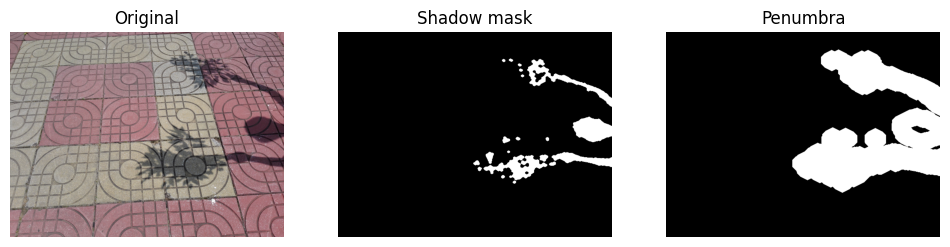

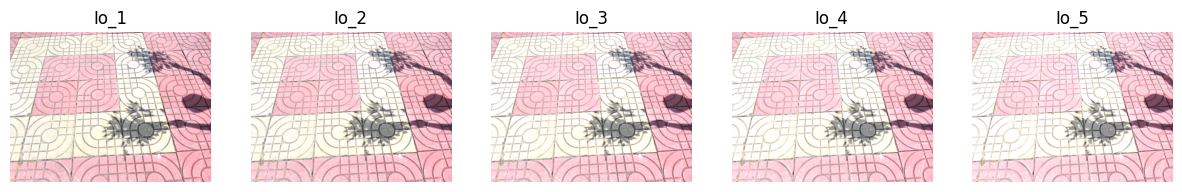

In [13]:
# Cell 6 - verify a random sample from train_A
import random
sample_folder = PROC_DIR / "train_A" / "images"
sample_list = list(sample_folder.glob("*.png"))
if not sample_list:
    print("No processed images found. Run previous cell.")
else:
    s = random.choice(sample_list)
    stem = s.stem
    img = imread_rgb(s)
    mask = cv2.imread(str(PROC_DIR / "train_A" / "masks" / f"{stem}_mask.png"), cv2.IMREAD_GRAYSCALE)
    pen = cv2.imread(str(PROC_DIR / "train_A" / "penumbra" / f"{stem}_pen.png"), cv2.IMREAD_GRAYSCALE)

    # load exposures Io1..IoN
    ios = []
    for i in range(1, N_EXPOSURES+1):
        ios.append(imread_rgb(PROC_DIR / "train_A" / "exposures" / f"{stem}_Io{i}.png"))

    # show
    show_triplet(img, mask, pen, titles=["Original", "Shadow mask", "Penumbra"])
    plt.figure(figsize=(15,6))
    for i, e in enumerate(ios, 1):
        plt.subplot(1, N_EXPOSURES, i); plt.imshow(e); plt.axis("off"); plt.title(f"Io_{i}")
    plt.show()


In [14]:
# PHASE 2 — Correct Dataset Loader

import os
import torch
from torch.utils.data import Dataset
import cv2
import numpy as np
from pathlib import Path

class ShadowRemovalDataset(Dataset):
    def __init__(self, proc_root, subset="train_A", K=5):
        """
        proc_root = '/kaggle/working/shadow-removal-project/data/processed'
        subset = 'train_A', 'train_B', 'test_A', etc.
        """
        self.root = Path(proc_root) / subset
        self.K = K

        self.img_dir = self.root / "images"
        self.mask_dir = self.root / "masks"
        self.pen_dir  = self.root / "penumbra"
        self.exp_dir  = self.root / "exposures"

        self.files = sorted([f.stem for f in self.img_dir.glob("*.png")])
        print(f"[INFO] Loaded {len(self.files)} samples from {subset}")

    def __len__(self):
        return len(self.files)

    def __getitem__(self, idx):
        name = self.files[idx]

        # Load A (shadow image)
        A = cv2.imread(str(self.img_dir / f"{name}.png"))
        A = cv2.cvtColor(A, cv2.COLOR_BGR2RGB).astype(np.float32) / 255.
        A = torch.tensor(A).permute(2,0,1)

        # Load mask
        mask = cv2.imread(str(self.mask_dir / f"{name}_mask.png"), 0)
        mask = (mask.astype(np.float32) / 255.)
        mask = torch.tensor(mask).unsqueeze(0)

        # Load penumbra
        pen = cv2.imread(str(self.pen_dir / f"{name}_pen.png"), 0)
        pen = (pen.astype(np.float32) / 255.)
        pen = torch.tensor(pen).unsqueeze(0)

        # Load exposures Io1..IoK
        Ios = []
        for i in range(1, self.K+1):
            Io = cv2.imread(str(self.exp_dir / f"{name}_Io{i}.png"))
            Io = cv2.cvtColor(Io, cv2.COLOR_BGR2RGB).astype(np.float32) / 255.
            Ios.append(Io)
        Io = torch.tensor(np.stack(Ios)).permute(0,3,1,2)

        return {"A": A, "mask": mask, "pen": pen, "Io": Io, "name": name}


In [15]:
PROC_DIR = "/kaggle/working/shadow-removal-project/data/processed"

train_ds = ShadowRemovalDataset(PROC_DIR, subset="train_A", K=5)
train_loader = DataLoader(train_ds, batch_size=4, shuffle=True, num_workers=2)

batch = next(iter(train_loader))
print("A:", batch["A"].shape)
print("Io:", batch["Io"].shape)
print("mask:", batch["mask"].shape)
print("pen:", batch["pen"].shape)


[INFO] Loaded 1330 samples from train_A
A: torch.Size([4, 3, 480, 640])
Io: torch.Size([4, 5, 3, 480, 640])
mask: torch.Size([4, 1, 480, 640])
pen: torch.Size([4, 1, 480, 640])


In [16]:
# U-Net building blocks
import torch
import torch.nn as nn
import torch.nn.functional as F

class ConvBlock(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True)
        )
    def forward(self,x): return self.net(x)

class Down(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.pool = nn.MaxPool2d(2)
        self.conv = ConvBlock(in_ch, out_ch)
    def forward(self,x): return self.conv(self.pool(x))

class Up(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.up = nn.ConvTranspose2d(in_ch, out_ch, 2, stride=2)
        self.conv = ConvBlock(in_ch, out_ch)
    def forward(self, x, skip):
        x = self.up(x)
        # pad if needed
        if x.size() != skip.size():
            x = F.interpolate(x, size=skip.shape[2:], mode='bilinear', align_corners=False)
        x = torch.cat([x, skip], dim=1)
        return self.conv(x)


In [17]:
class FusionNetSmall(nn.Module):
    def __init__(self, in_ch=3+3*5+1, base=32, K=5):
        """
        in_ch: channels = A(3) + stacked Io (3*K) + mask(1)
        outputs: weight maps for K exposures (K x 1 x H x W) -> softmax across K
        """
        super().__init__()
        self.K = K
        self.enc1 = ConvBlock(in_ch, base)
        self.enc2 = Down(base, base*2)
        self.enc3 = Down(base*2, base*4)

        self.mid = ConvBlock(base*4, base*8)

        self.up3 = Up(base*8, base*4)
        self.up2 = Up(base*4, base*2)
        self.up1 = Up(base*2, base)

        self.head = nn.Conv2d(base, K, kernel_size=1)  # raw weights per exposure

    def forward(self, A, Io, mask):
        # Io shape: (B, K, 3, H, W) -> flatten to channels
        B,K,_,H,W = Io.shape
        Io_flat = Io.view(B, K*3, H, W)
        x = torch.cat([A, Io_flat, mask], dim=1)
        e1 = self.enc1(x)
        e2 = self.enc2(e1)
        e3 = self.enc3(e2)
        m = self.mid(e3)
        u3 = self.up3(m, e3)
        u2 = self.up2(u3, e2)
        u1 = self.up1(u2, e1)
        logits = self.head(u1)  # (B, K, H, W)
        # softmax across K to obtain positive weights summing to 1
        weights = torch.softmax(logits.view(B, self.K, -1), dim=1).view(B, self.K, H, W)
        return weights


In [18]:
class RefineNetSmall(nn.Module):
    def __init__(self, in_ch=3+3+1+1, base=32):
        # inputs: I_hat (3), A(3), mask(1), pen(1) -> concat channels
        super().__init__()
        self.enc1 = ConvBlock(in_ch, base)
        self.enc2 = Down(base, base*2)
        self.enc3 = Down(base*2, base*4)
        self.mid = ConvBlock(base*4, base*8)
        self.up3 = Up(base*8, base*4)
        self.up2 = Up(base*4, base*2)
        self.up1 = Up(base*2, base)
        self.head = nn.Conv2d(base, 3, kernel_size=1)
    def forward(self, I_hat, A, mask, pen):
        x = torch.cat([I_hat, A, mask, pen], dim=1)
        e1 = self.enc1(x)
        e2 = self.enc2(e1)
        e3 = self.enc3(e2)
        m = self.mid(e3)
        u3 = self.up3(m, e3)
        u2 = self.up2(u3, e2)
        u1 = self.up1(u2, e1)
        out = torch.sigmoid(self.head(u1))
        return out

# fusion operator
def fuse_exposures(weights, Io):
    # weights: (B,K,H,W), Io: (B,K,3,H,W)
    B,K,H,W = weights.shape
    # expand weights to color channels
    w = weights.unsqueeze(2)  # (B,K,1,H,W)
    fused = (w * Io).sum(dim=1)  # sum over K -> (B,3,H,W)
    return fused


In [19]:
import torch.nn.functional as F

def laplacian(x):
    kernel = torch.tensor(
        [[[[0,-1,0],[-1,4,-1],[0,-1,0]]]],
        dtype=torch.float32, device=x.device
    )
    kernel = kernel.repeat(x.shape[1],1,1,1)
    return F.conv2d(x, kernel, padding=1, groups=x.shape[1])

def boundary_loss(pred, src, gt, mask):
    lp_pred = laplacian(pred)
    lp_src = laplacian(src)
    lp_gt  = laplacian(gt)

    non_mask = 1.0 - mask

    t1 = ((lp_pred - lp_src)**2 * non_mask).mean()
    t2 = ((lp_pred - lp_gt)**2 * mask).mean()
    return t1 + t2

def total_loss(pred, gt, src, mask, lambda_bd=0.1):
    l1 = F.l1_loss(pred, gt)
    bd = boundary_loss(pred, src, gt, mask)
    return l1 + lambda_bd*bd, l1, bd


In [20]:
def fuse_exposures(weights, Io):
    # weights: (B,K,H,W)
    # Io: (B,K,3,H,W)
    w = weights.unsqueeze(2)               # (B,K,1,H,W)
    out = (w * Io).sum(dim=1)             # weighted sum over K
    return torch.clamp(out, 0, 1)


In [21]:
def lab_rmse_tensor(pred, gt):
    p = (pred*255).permute(0,2,3,1).cpu().numpy().astype(np.uint8)
    g = (gt*255).permute(0,2,3,1).cpu().numpy().astype(np.uint8)

    import cv2
    rmses = []
    for i in range(p.shape[0]):
        pl = cv2.cvtColor(p[i], cv2.COLOR_RGB2LAB).astype(np.float32)
        gl = cv2.cvtColor(g[i], cv2.COLOR_RGB2LAB).astype(np.float32)
        rmses.append(np.sqrt(np.mean((pl - gl)**2)))
    return float(np.mean(rmses))


In [22]:
from torch.amp import autocast, GradScaler
scaler = GradScaler('cuda')

def train_one_epoch(epoch, model_fusion, model_refine, loader, optimizer, device):
    model_fusion.train()
    model_refine.train()

    total_loss = 0
    for batch in loader:
        A = batch["A"].to(device)
        Io = batch["Io"].to(device)
        B = batch["B"].to(device)
        mask = batch["mask"].to(device)
        pen = batch["pen"].to(device)

        optimizer.zero_grad()

        with autocast(device_type='cuda'):
            weights = model_fusion(A, Io, mask)
            I_hat = fuse_exposures(weights, Io)
            I_ref = model_refine(I_hat, A, mask, pen)

            loss, l1, bd = total_loss(I_ref, B, A, mask)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        total_loss += loss.item() * A.size(0)

    return total_loss / len(loader.dataset)


In [23]:
def validate(model_fusion, model_refine, loader, device):
    model_fusion.eval()
    model_refine.eval()

    total_rmse = 0
    with torch.no_grad():
        for batch in loader:
            A = batch["A"].to(device)
            Io = batch["Io"].to(device)
            B = batch["B"].to(device)
            mask = batch["mask"].to(device)
            pen = batch["pen"].to(device)

            weights = model_fusion(A, Io, mask)
            I_hat = fuse_exposures(weights, Io)
            I_ref = model_refine(I_hat, A, mask, pen)

            rmse = lab_rmse_tensor(I_ref, B)
            total_rmse += rmse * A.size(0)

    return total_rmse / len(loader.dataset)


In [24]:
def fuse_exposures(weights, Io):
    # weights: (B, K, H, W)
    # Io:      (B, K, 3, H, W)
    w = weights.unsqueeze(2)  # (B,K,1,H,W)
    fused = (w * Io).sum(dim=1)  # -> (B,3,H,W)
    return fused


In [25]:
import torch
import torch.nn as nn
import torch.nn.functional as F

# ---- Basic Conv Block ----
class ConvBlock(nn.Module):
    def __init__(self, in_c, out_c):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_c, out_c, 3, padding=1),
            nn.BatchNorm2d(out_c),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_c, out_c, 3, padding=1),
            nn.BatchNorm2d(out_c),
            nn.ReLU(inplace=True)
        )
    def forward(self, x):
        return self.block(x)


# ---- U-Net Down/Up ----
class Down(nn.Module):
    def __init__(self, in_c, out_c):
        super().__init__()
        self.maxpool = nn.MaxPool2d(2)
        self.conv = ConvBlock(in_c, out_c)

    def forward(self, x):
        return self.conv(self.maxpool(x))


class Up(nn.Module):
    def __init__(self, in_c, out_c):
        super().__init__()
        self.up = nn.ConvTranspose2d(in_c, in_c//2, 2, stride=2)
        self.conv = ConvBlock(in_c, out_c)

    def forward(self, x1, x2):
        x1 = self.up(x1)
        diffY = x2.size(2) - x1.size(2)
        diffX = x2.size(3) - x1.size(3)
        x1 = F.pad(x1, [diffX//2, diffX - diffX//2,
                        diffY//2, diffY - diffY//2])
        x = torch.cat([x2, x1], dim=1)
        return self.conv(x)



# ---------------------------
#     FusionNet
# ---------------------------
class FusionNet(nn.Module):
    def __init__(self, K=5):
        super().__init__()
        self.K = K

        in_channels = 3 + (3*K) + 1   # A + Io exposures + mask

        self.inc = ConvBlock(in_channels, 32)
        self.down1 = Down(32, 64)
        self.down2 = Down(64, 128)
        self.down3 = Down(128, 256)

        self.up1 = Up(256, 128)
        self.up2 = Up(128, 64)
        self.up3 = Up(64, 32)

        self.outc = nn.Conv2d(32, K, 1)

    def forward(self, A, Io, mask):
        # Io shape: (B,K,3,H,W) → flatten to (B,3K,H,W)
        B, K, C, H, W = Io.shape
        Io_flat = Io.reshape(B, K*C, H, W)

        x = torch.cat([A, Io_flat, mask], dim=1)

        x1 = self.inc(x)
        x2 = self.down1(x1)
        x3 = self.down2(x2)
        x4 = self.down3(x3)

        x = self.up1(x4, x3)
        x = self.up2(x, x2)
        x = self.up3(x, x1)

        weights = self.outc(x)     # (B,K,H,W)
        weights = torch.softmax(weights, dim=1)
        return weights


In [26]:
def fuse_exposures(weights, Io):
    """
    weights: (B,K,H,W)
    Io:      (B,K,3,H,W)
    """
    B, K, C, H, W = Io.shape
    w = weights.unsqueeze(2)   # (B,K,1,H,W)
    fused = (w * Io).sum(dim=1)  # → (B,3,H,W)
    return fused


In [27]:
class RefineNet(nn.Module):
    def __init__(self):
        super().__init__()

        in_channels = 3 + 3 + 1 + 1   # I_hat + A + mask + penumbra

        self.inc = ConvBlock(in_channels, 32)
        self.down1 = Down(32, 64)
        self.down2 = Down(64, 128)

        self.up1 = Up(128, 64)
        self.up2 = Up(64, 32)

        self.outc = nn.Conv2d(32, 3, 1)

    def forward(self, I_hat, A, mask, pen):
        x = torch.cat([I_hat, A, mask, pen], dim=1)

        x1 = self.inc(x)
        x2 = self.down1(x1)
        x3 = self.down2(x2)

        x = self.up1(x3, x2)
        x = self.up2(x, x1)

        out = torch.sigmoid(self.outc(x))
        return out


In [28]:
model_fusion = FusionNet(K=5).to(device)
model_refine = RefineNet().to(device)

print("FusionNet params:", sum(p.numel() for p in model_fusion.parameters()))
print("RefineNet params:", sum(p.numel() for p in model_refine.parameters()))


FusionNet params: 1933157
RefineNet params: 469315


In [29]:
# Cell: models_and_losses
import torch
import torch.nn as nn
import torch.nn.functional as F

# -------------------------
# Small U-Net encoder/decoder blocks
# -------------------------
class ConvBlock(nn.Module):
    def __init__(self, in_ch, out_ch, kernel=3, stride=1, padding=1):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, kernel, stride, padding, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, kernel, stride, padding, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
        )
    def forward(self, x): return self.net(x)

class Down(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.pool = nn.MaxPool2d(2)
        self.conv = ConvBlock(in_ch, out_ch)
    def forward(self, x): return self.conv(self.pool(x))

class Up(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.up = nn.ConvTranspose2d(in_ch, out_ch, kernel_size=2, stride=2)
        self.conv = ConvBlock(in_ch, out_ch)
    def forward(self, x, skip):
        x = self.up(x)
        # center crop skip to x size if needed (should match if input sizes are powers of two)
        if x.shape != skip.shape:
            # simple resize skip to x
            skip = F.interpolate(skip, size=x.shape[2:], mode='bilinear', align_corners=False)
        x = torch.cat([x, skip], dim=1)
        return self.conv(x)

# -------------------------
# FusionNet: outputs K weight maps (unnormalized). Input: concatenated A + mask
# -------------------------
class FusionNet(nn.Module):
    def __init__(self, in_ch=4, base_ch=32, K=5):
        super().__init__()
        self.K = K
        self.inc = ConvBlock(in_ch, base_ch)     # input conv
        self.down1 = Down(base_ch, base_ch*2)
        self.down2 = Down(base_ch*2, base_ch*4)
        self.down3 = Down(base_ch*4, base_ch*8)
        self.bridge = ConvBlock(base_ch*8, base_ch*8)
        self.up3 = Up(base_ch*8, base_ch*4)
        self.up2 = Up(base_ch*4, base_ch*2)
        self.up1 = Up(base_ch*2, base_ch)
        self.out_conv = nn.Conv2d(base_ch, K, kernel_size=1)  # per-pixel K logits

    def forward(self, A, mask):
        # A: (B,3,H,W), mask: (B,1,H,W)
        x = torch.cat([A, mask], dim=1)  # (B,4,H,W)
        x1 = self.inc(x)
        x2 = self.down1(x1)
        x3 = self.down2(x2)
        x4 = self.down3(x3)
        b = self.bridge(x4)
        u3 = self.up3(b, x3)
        u2 = self.up2(u3, x2)
        u1 = self.up1(u2, x1)
        logits = self.out_conv(u1)  # (B,K,H,W)
        # softmax over K channels so they sum to 1 per-pixel
        weights = F.softmax(logits, dim=1)
        return weights

# -------------------------
# RefineNet: small U-Net that refines fused image
# Input: I_hat (B,3,H,W), A (B,3,H,W), mask (B,1,H,W), pen (B,1,H,W)
# Output: refined RGB (B,3,H,W)
# -------------------------
class RefineNet(nn.Module):
    def __init__(self, in_ch=8, base_ch=32):
        super().__init__()
        self.inc = ConvBlock(in_ch, base_ch)    # I_hat(3) + A(3) + mask(1) + pen(1) = 8
        self.down1 = Down(base_ch, base_ch*2)
        self.down2 = Down(base_ch*2, base_ch*4)
        self.bridge = ConvBlock(base_ch*4, base_ch*4)
        self.up2 = Up(base_ch*4, base_ch*2)
        self.up1 = Up(base_ch*2, base_ch)
        self.out_conv = nn.Sequential(
            nn.Conv2d(base_ch, 3, kernel_size=1),
            nn.Sigmoid()  # output in [0,1]
        )

    def forward(self, I_hat, A, mask, pen):
        x = torch.cat([I_hat, A, mask, pen], dim=1)  # (B,8,H,W)
        x1 = self.inc(x)
        x2 = self.down1(x1)
        x3 = self.down2(x2)
        b = self.bridge(x3)
        u2 = self.up2(b, x2)
        u1 = self.up1(u2, x1)
        out = self.out_conv(u1)
        return out

# -------------------------
# fuse_exposures utility
# Io: (B,K,3,H,W), weights: (B,K,H,W)
# -------------------------
def fuse_exposures(weights, Io):
    # weights: (B,K,H,W) -> expand to (B,K,3,H,W)
    B,K,H,W = weights.shape
    w = weights.view(B,K,1,H,W)            # (B,K,1,H,W)
    # Io expected float in [0,1] or [0,255], ensure type float
    Io_f = Io.float()
    fused = (w * Io_f).sum(dim=1)          # sum over K -> (B,3,H,W)
    # clamp to [0,1] if Io was normalized; but training expects [0,1]
    if fused.max() > 1.1:
        # likely Io in [0,255], convert
        fused = fused / 255.0
    return fused.clamp(0.0, 1.0)

# -------------------------
# losses including boundary loss (same as we discussed)
# -------------------------
def laplacian(x):
    # x: (B,C,H,W)
    kernel = torch.tensor([[[[0,-1,0],[-1,4,-1],[0,-1,0]]]], dtype=torch.float32, device=x.device)
    kernel = kernel.repeat(x.shape[1],1,1,1)  # (C,1,3,3)
    out = F.conv2d(x, kernel, padding=1, groups=x.shape[1])
    return out

def boundary_loss(pred, src, gt, mask):
    lp_pred = laplacian(pred)
    lp_src  = laplacian(src)
    lp_gt   = laplacian(gt)
    non_mask = 1.0 - mask
    term1 = (((lp_pred - lp_src)**2) * non_mask).mean()
    term2 = (((lp_pred - lp_gt)**2) * mask).mean()
    return term1 + term2

def total_loss(pred, gt, src, mask, lambda_bd=0.1):
    l1 = F.l1_loss(pred, gt)
    bd = boundary_loss(pred, src, gt, mask)
    return l1 + lambda_bd * bd, l1, bd


In [30]:
# Cell: dataset_and_loader
import os, glob
import torch
from torch.utils.data import Dataset, DataLoader
import numpy as np
import cv2

class ISTDProcDataset(Dataset):
    def __init__(self, proc_root, split="train_A", K=5, img_size=None):
        """
        proc_root: Path to processed directory (PROC_DIR)
        split: e.g., 'train_A' or 'test_A' (we will use train_A for training)
        Expects structure:
          PROC_DIR / split / images / <stem>.png
          PROC_DIR / split / masks / <stem>_mask.png
          PROC_DIR / split / penumbra / <stem>_pen.png
          PROC_DIR / split / exposures / <stem>_Io{i}.png
        """
        self.root = proc_root
        self.split = split
        self.K = K
        self.img_size = img_size
        images_dir = os.path.join(proc_root, split, "images")
        self.files = sorted([p for p in os.listdir(images_dir) if p.endswith(".png")])
        self.images_dir = images_dir
        self.masks_dir = os.path.join(proc_root, split, "masks")
        self.pen_dir = os.path.join(proc_root, split, "penumbra")
        self.exposures_dir = os.path.join(proc_root, split, "exposures")
        print(f"[INFO] Loaded {len(self.files)} samples from {self.images_dir}")

    def __len__(self):
        return len(self.files)

    def __getitem__(self, idx):
        name = self.files[idx]
        stem = os.path.splitext(name)[0]
        # read A
        A = cv2.imread(os.path.join(self.images_dir, name))
        A = cv2.cvtColor(A, cv2.COLOR_BGR2RGB).astype(np.float32) / 255.0
        # read B (GT): in ISTD original B is in train_B or processed train_B; we saved exposures separately.
        # For processed layout we assume "train_B" images located in the corresponding processed folder images or B copied as metadata earlier.
        # try to find B in sibling processed folder train_B/images
        sibling = self.split.replace("A","B")
        B_path = os.path.join(os.path.dirname(self.images_dir), sibling, "images", name)
        if not os.path.exists(B_path):
            # fallback: try same folder with _B suffix (if you used earlier simple pipeline)
            B_path = os.path.join(self.images_dir, f"{stem}_B.png")
        B = cv2.imread(B_path)
        if B is None:
            # if still missing, return zeros (should not happen)
            B = np.zeros_like(A)
        else:
            B = cv2.cvtColor(B, cv2.COLOR_BGR2RGB).astype(np.float32) / 255.0

        mask = cv2.imread(os.path.join(self.masks_dir, f"{stem}_mask.png"), cv2.IMREAD_GRAYSCALE)
        pen  = cv2.imread(os.path.join(self.pen_dir, f"{stem}_pen.png"), cv2.IMREAD_GRAYSCALE)
        # exposures Io1..IoK
        Io_list = []
        for i in range(1, self.K+1):
            p = os.path.join(self.exposures_dir, f"{stem}_Io{i}.png")
            io = cv2.imread(p)
            io = cv2.cvtColor(io, cv2.COLOR_BGR2RGB).astype(np.float32) / 255.0
            Io_list.append(io)
        # optionally resize
        if self.img_size:
            h,w = self.img_size
            A = cv2.resize(A, (w,h), interpolation=cv2.INTER_LINEAR)
            B = cv2.resize(B, (w,h), interpolation=cv2.INTER_LINEAR)
            mask = cv2.resize(mask, (w,h), interpolation=cv2.INTER_NEAREST)
            pen  = cv2.resize(pen, (w,h), interpolation=cv2.INTER_NEAREST)
            Io_list = [cv2.resize(x, (w,h), interpolation=cv2.INTER_LINEAR) for x in Io_list]

        # convert to tensors
        A = torch.tensor(A).permute(2,0,1).float()
        B = torch.tensor(B).permute(2,0,1).float()
        Io = torch.tensor(np.stack(Io_list, axis=0)).permute(0,3,1,2).float()  # (K,3,H,W)
        mask = torch.tensor((mask.astype(np.float32)/255.0)).unsqueeze(0).float()
        pen  = torch.tensor((pen.astype(np.float32)/255.0)).unsqueeze(0).float()

        return {"A":A, "B":B, "Io":Io, "mask":mask, "pen":pen, "name":stem}

# ---------------------
# instantiate loaders (adjust PROC_DIR path)
# ---------------------
PROC_DIR = "/kaggle/working/shadow-removal-project/data/processed"  # your processed dir
# using train_A for training and test_A for validation (paper trains using paired triplets)
train_ds = ISTDProcDataset(PROC_DIR, split="train_A", K=5, img_size=(480,640))
val_ds   = ISTDProcDataset(PROC_DIR, split="test_A",  K=5, img_size=(480,640))

BATCH = 4
train_loader = DataLoader(train_ds, batch_size=BATCH, shuffle=True, num_workers=2, pin_memory=True)
val_loader   = DataLoader(val_ds,   batch_size=1,   shuffle=False, num_workers=1, pin_memory=True)


[INFO] Loaded 1330 samples from /kaggle/working/shadow-removal-project/data/processed/train_A/images
[INFO] Loaded 540 samples from /kaggle/working/shadow-removal-project/data/processed/test_A/images


In [31]:
# Cell: instantiation
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
K = 5

model_fusion = FusionNet(in_ch=4, base_ch=32, K=K).to(device)
model_refine = RefineNet(in_ch=8, base_ch=32).to(device)

# optimizer (joint)
params = list(model_fusion.parameters()) + list(model_refine.parameters())
optimizer = torch.optim.AdamW(params, lr=1e-4, weight_decay=1e-6)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, 'min', factor=0.5, patience=3, min_lr=1e-7)

print("FusionNet params:", sum(p.numel() for p in model_fusion.parameters()))
print("RefineNet params:", sum(p.numel() for p in model_refine.parameters()))


FusionNet params: 3108101
RefineNet params: 764099


In [46]:
import time
from torch.amp import GradScaler, autocast
scaler = GradScaler('cuda')


def lab_rmse_tensor(pred, gt):
    # pred,gt in [0,1]
    p = (pred*255).permute(0,2,3,1).cpu().numpy().astype("uint8")
    g = (gt*255).permute(0,2,3,1).cpu().numpy().astype("uint8")
    import cv2, numpy as np
    rmses = []
    for i in range(p.shape[0]):
        p_lab = cv2.cvtColor(p[i], cv2.COLOR_RGB2LAB).astype(np.float32)
        g_lab = cv2.cvtColor(g[i], cv2.COLOR_RGB2LAB).astype(np.float32)
        rmse = np.sqrt(np.mean((p_lab - g_lab)**2))
        rmses.append(rmse)
    return float(np.mean(rmses))

def train_one_epoch(epoch, model_fusion, model_refine, loader, optimizer, device):
    model_fusion.train(); model_refine.train()
    running_loss = 0.0
    it = 0
    for batch in loader:
        A = batch["A"].to(device)
        Io = batch["Io"].to(device)           # (B,K,3,H,W)
        B = batch["B"].to(device)
        mask = batch["mask"].to(device)
        pen = batch["pen"].to(device)

        optimizer.zero_grad()
        with autocast(device_type='cuda'):
            weights = model_fusion(A, mask)         # (B,K,H,W)
            I_hat = fuse_exposures(weights, Io)     # (B,3,H,W)
            I_ref = model_refine(I_hat, A, mask, pen) # (B,3,H,W)
            loss_total, l1, bd = total_loss(I_ref, B, A, mask)
        scaler.scale(loss_total).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(params, 5.0)
        scaler.step(optimizer)
        scaler.update()

        running_loss += loss_total.item()
        it += 1
    return running_loss / it

def validate(model_fusion, model_refine, loader, device):
    model_fusion.eval(); model_refine.eval()
    tot_rmse = 0.0
    it = 0
    with torch.no_grad():
        for batch in loader:
            A = batch["A"].to(device)
            Io = batch["Io"].to(device)
            B = batch["B"].to(device)
            mask = batch["mask"].to(device)
            pen = batch["pen"].to(device)

            weights = model_fusion(A, mask)
            I_hat = fuse_exposures(weights, Io)
            I_ref = model_refine(I_hat, A, mask, pen)
            rmse = lab_rmse_tensor(I_ref, B)
            tot_rmse += rmse
            it += 1
    return tot_rmse / it

# checkpoint helpers
def save_checkpoint(path, model_fusion, model_refine, optimizer, epoch, best=False):
    torch.save({
        'epoch': epoch,
        'fusion_state': model_fusion.state_dict(),
        'refine_state': model_refine.state_dict(),
        'optimizer': optimizer.state_dict()
    }, path)
    print(f"Saved checkpoint: {path}")

In [33]:
class ISTDDataset(Dataset):
    def __init__(self, root, split="train", K=5):
        self.root = Path(root)
        self.split = split
        self.K = K

        self.A_dir = self.root / f"{split}_A"
        self.B_dir = self.root / f"{split}_B"

        self.A_img_dir = self.A_dir / "images"
        self.B_img_dir = self.B_dir / "images"

        self.mask_dir = self.A_dir / "masks"
        self.pen_dir  = self.A_dir / "penumbra"
        self.exp_dir  = self.A_dir / "exposures"

        self.names = sorted([p.stem for p in self.A_img_dir.glob("*.png")])
        print(f"[INFO] Loaded {len(self.names)} samples from {split}_A")

    def __len__(self):
        return len(self.names)

    def __getitem__(self, idx):
        name = self.names[idx]

        # ----- Load A (shadow image) -----
        A = cv2.imread(str(self.A_img_dir / f"{name}.png"))
        A = cv2.cvtColor(A, cv2.COLOR_BGR2RGB).astype(np.float32)/255.

        # ----- Load B (shadow-free GT) -----
        B = cv2.imread(str(self.B_img_dir / f"{name}.png"))
        B = cv2.cvtColor(B, cv2.COLOR_BGR2RGB).astype(np.float32)/255.

        # ----- Shadow mask -----
        mask = cv2.imread(str(self.mask_dir / f"{name}_mask.png"), 0)
        mask = (mask.astype(np.float32)/255.).reshape(1, mask.shape[0], mask.shape[1])

        # ----- Penumbra -----
        pen = cv2.imread(str(self.pen_dir / f"{name}_pen.png"), 0)
        pen = (pen.astype(np.float32)/255.).reshape(1, pen.shape[0], pen.shape[1])

        # ----- Load exposures Io1..IoK -----
        Io_list = []
        for k in range(1, self.K+1):
            Io = cv2.imread(str(self.exp_dir / f"{name}_Io{k}.png"))
            Io = cv2.cvtColor(Io, cv2.COLOR_BGR2RGB).astype(np.float32)/255.
            Io_list.append(Io)

        A = torch.tensor(A).permute(2,0,1)
        B = torch.tensor(B).permute(2,0,1)
        Io = torch.tensor(np.stack(Io_list)).permute(0,3,1,2)
        mask = torch.tensor(mask)
        pen = torch.tensor(pen)

        return {"A":A, "B":B, "Io":Io, "mask":mask, "pen":pen, "name":name}


In [38]:
train_dataset = ISTDDataset(PROC_DIR, "train")
train_loader = DataLoader(train_dataset, batch_size=4, shuffle=True)

[INFO] Loaded 1330 samples from train_A


In [42]:
EPOCHS = 20
best_rmse = 9999
save_path = "/kaggle/working/shadow-removal-model.pth"

for epoch in range(1, EPOCHS+1):
    print(f"\n==================== EPOCH {epoch}/{EPOCHS} ====================")

    # TRAIN
    train_loss = train_one_epoch(epoch, model_fusion, model_refine,
                                 train_loader, optimizer, device)
    print(f"Train Loss: {train_loss:.6f}")

    # VALIDATE
    val_rmse = validate(model_fusion, model_refine, val_loader, device)
    print(f"Validation RMSE: {val_rmse:.4f}")

    # LR scheduling
    scheduler.step(val_rmse)

    # SAVE BEST CHECKPOINT
    if val_rmse < best_rmse:
        best_rmse = val_rmse
        save_checkpoint(save_path, model_fusion, model_refine, optimizer, epoch)
        print("🔥 Best model saved!")




==================== EPOCH 1/20 ====================
Train Loss: 0.376314
Validation RMSE: 75.5265
Saved checkpoint: /kaggle/working/shadow-removal-model.pth
🔥 Best model saved!

==================== EPOCH 2/20 ====================
Train Loss: 0.283491
Validation RMSE: 72.4103
Saved checkpoint: /kaggle/working/shadow-removal-model.pth
🔥 Best model saved!

==================== EPOCH 3/20 ====================
Train Loss: 0.220388
Validation RMSE: 61.4993
Saved checkpoint: /kaggle/working/shadow-removal-model.pth
🔥 Best model saved!

==================== EPOCH 4/20 ====================
Train Loss: 0.172211
Validation RMSE: 58.6530
Saved checkpoint: /kaggle/working/shadow-removal-model.pth
🔥 Best model saved!

==================== EPOCH 5/20 ====================
Train Loss: 0.139215
Validation RMSE: 52.7883
Saved checkpoint: /kaggle/working/shadow-removal-model.pth
🔥 Best model saved!

==================== EPOCH 6/20 ====================
Train Loss: 0.117403
Validation RMSE: 62.8264

====

In [43]:
checkpoint = torch.load("/kaggle/working/shadow-removal-model.pth")

model_fusion.load_state_dict(checkpoint["fusion_state"])
model_refine.load_state_dict(checkpoint["refine_state"])
model_fusion.eval()
model_refine.eval()

print("✔ Model loaded for inference!")


✔ Model loaded for inference!


In [44]:
def infer_shadow_removal(img_rgb, model_fusion, model_refine, n_exposures=5):
    mask, pen = generate_shadow_and_penumbra(img_rgb)
    ios, alphas, betas = compute_exposures(img_rgb, mask, n_exposures)

    A = torch.tensor(img_rgb/255.0).permute(2,0,1).unsqueeze(0).float().to(device)
    mask_t = torch.tensor(mask/255.0).unsqueeze(0).unsqueeze(0).float().to(device)
    pen_t = torch.tensor(pen/255.0).unsqueeze(0).unsqueeze(0).float().to(device)

    Io = torch.tensor(np.stack(ios)/255.0).permute(0,3,1,2).unsqueeze(0).float().to(device)

    with torch.no_grad():
        weights = model_fusion(A, mask_t)
        I_hat = fuse_exposures(weights, Io)
        I_ref = model_refine(I_hat, A, mask_t, pen_t)

    return I_ref[0].permute(1,2,0).cpu().numpy()


Using test image: /kaggle/working/shadow-removal-project/data/processed/test_A/images/118-12.png


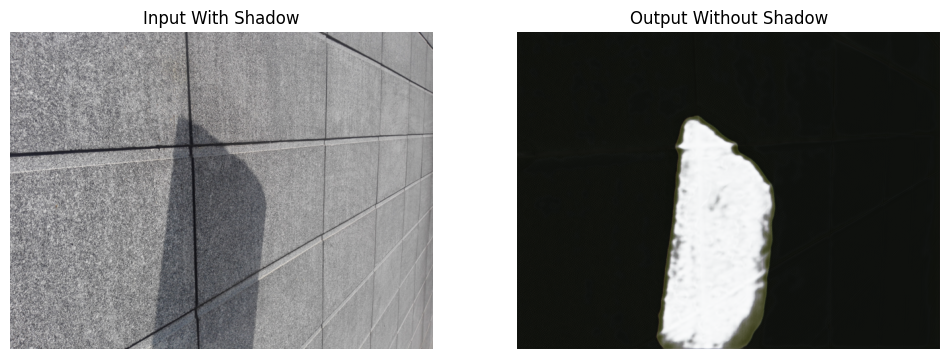

In [47]:
import os
import random

# Construct the path to the test_A images directory
test_images_dir = os.path.join(PROC_DIR, "test_A", "images")

# List all files in the directory
all_test_images = sorted(os.listdir(test_images_dir))

if not all_test_images:
    print(f"Error: No images found in {test_images_dir}. Please check data processing steps.")
    raise FileNotFoundError(f"No images found in {test_images_dir}")

# Pick a random image from the found files
test_img_fname = random.choice(all_test_images)
test_img_path = os.path.join(test_images_dir, test_img_fname)

print(f"Using test image: {test_img_path}")

inp = cv2.cvtColor(cv2.imread(test_img_path), cv2.COLOR_BGR2RGB)

out = infer_shadow_removal(inp, model_fusion, model_refine)

plt.figure(figsize=(12,5))
plt.subplot(1,2,1); plt.imshow(inp); plt.title("Input With Shadow"); plt.axis("off")
plt.subplot(1,2,2); plt.imshow(out); plt.title("Output Without Shadow"); plt.axis("off")
plt.show()

In [48]:
batch = next(iter(val_loader))
A = batch["A"].to(device)
Io = batch["Io"].to(device)
mask = batch["mask"].to(device)
pen = batch["pen"].to(device)

weights = model_fusion(A, mask)
I_hat = fuse_exposures(weights, Io)
I_ref = model_refine(I_hat, A, mask, pen)


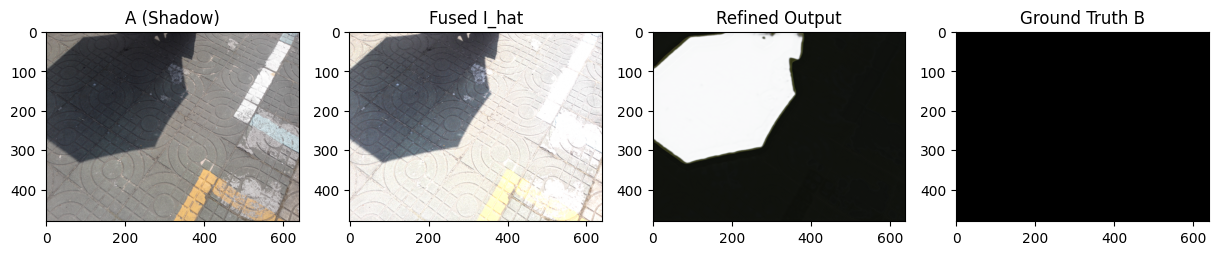

In [49]:
plt.figure(figsize=(15,5))
plt.subplot(1,4,1); plt.imshow(A[0].permute(1,2,0).cpu().detach()); plt.title("A (Shadow)")
plt.subplot(1,4,2); plt.imshow(I_hat[0].permute(1,2,0).cpu().detach()); plt.title("Fused I_hat")
plt.subplot(1,4,3); plt.imshow(I_ref[0].permute(1,2,0).cpu().detach()); plt.title("Refined Output")
plt.subplot(1,4,4); plt.imshow(batch["B"][0].permute(1,2,0).cpu().detach()); plt.title("Ground Truth B")
plt.show()

In [50]:
def shadow_remove_inference(model_fusion, model_refine, img_path):
    img = cv2.imread(img_path)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    mask, pen = generate_shadow_mask(img)
    exposures, _, _ = compute_exposures(img, mask)

    A = torch.tensor(img/255.).permute(2,0,1).unsqueeze(0).float().to(device)
    mask = torch.tensor(mask/255.).unsqueeze(0).unsqueeze(0).float().to(device)
    pen  = torch.tensor(pen/255.).unsqueeze(0).unsqueeze(0).float().to(device)

    Io = torch.tensor(np.stack(exposures)).unsqueeze(0).permute(0,1,4,2,3).float().to(device)

    # forward pass
    weights = model_fusion(A, mask)
    I_hat   = fuse_exposures(weights, Io)
    I_ref   = model_refine(I_hat, A, mask, pen)

    out = (I_ref[0].permute(1,2,0).cpu().numpy()*255).astype(np.uint8)
    return out


In [51]:
def shadow_remove_inference(model_fusion, model_refine, img_path):

    # ---- Load image ----
    img = cv2.imread(img_path)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB).astype(np.uint8)

    # ---- Generate shadow mask & penumbra (Correct Function) ----
    mask, pen = generate_shadow_and_penumbra(img)

    # ---- Generate multi-exposures Io1..Io5 ----
    ios, alphas, betas = compute_exposures(img, mask, n_exposures=5)

    # ---- Convert to tensors ----
    A = torch.tensor(img/255.0).permute(2,0,1).unsqueeze(0).float().to(device)
    mask_t = torch.tensor(mask/255.0).unsqueeze(0).unsqueeze(0).float().to(device)
    pen_t  = torch.tensor(pen /255.0).unsqueeze(0).unsqueeze(0).float().to(device)

    Io = torch.tensor(np.stack(ios)/255.0).permute(0,3,1,2)   # (K,3,H,W)
    Io = Io.unsqueeze(0).float().to(device)                   # (1,K,3,H,W)

    model_fusion.eval()
    model_refine.eval()

    with torch.no_grad():
        weights = model_fusion(A, mask_t)
        I_hat = fuse_exposures(weights, Io)
        I_ref = model_refine(I_hat, A, mask_t, pen_t)

    out = (I_ref[0].permute(1,2,0).cpu().numpy() * 255).astype(np.uint8)
    return out


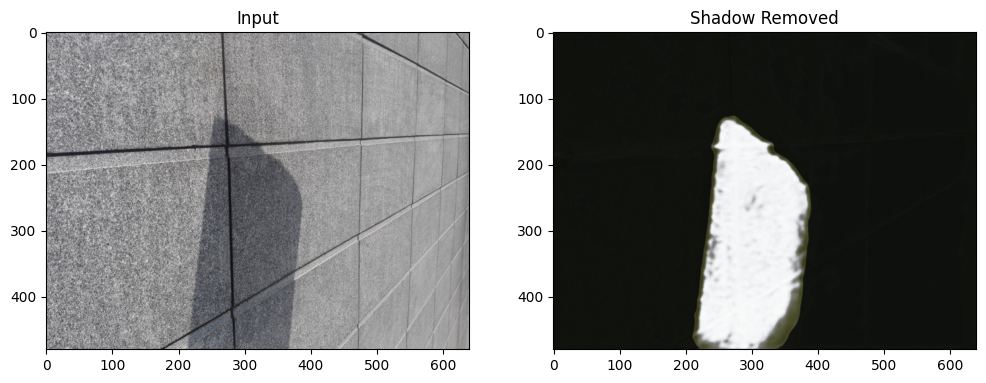

In [53]:
img_path = test_img_path # Using the valid path from the previous cell

out = shadow_remove_inference(model_fusion, model_refine, img_path)

plt.figure(figsize=(12,5))
# Read the image again for display, using the confirmed valid path
input_image_for_display = cv2.cvtColor(cv2.imread(img_path), cv2.COLOR_BGR2RGB)
plt.subplot(1,2,1); plt.imshow(input_image_for_display); plt.title("Input")
plt.subplot(1,2,2); plt.imshow(out); plt.title("Shadow Removed")
plt.show()